# Feature engineering y modelos de hazard: selección temporal sin fuga

**Pregunta:** entre clientes aún elegibles, ¿quién convierte este mes? Evaluamos nuevas representaciones,
ablaciones y familias de modelos sobre el mismo objetivo mensual. No se exige que la complejidad mejore.

**Correcciones al trabajo anterior:** el baseline usó noviembre para early stopping; su AUC 0.6190
es exploratoria. El baseline a tres meses entrenó con cohortes de julio/agosto cuyos horizontes
no habían madurado al comienzo de septiembre. No se reutiliza esa formulación aquí.
Noviembre YA fue inspeccionado en trabajos anteriores: no es un holdout virgen. En este experimento
no se permite seleccionar features, hiperparámetros o pesos con sus etiquetas. Una estimación externa
completamente independiente requeriría etiquetas de diciembre u otro periodo nuevo.

Todos los modelos seleccionan usando AUC media en agosto, septiembre y octubre. Se congelan candidatos,
número de árboles y mezcla antes de abrir resultados de noviembre. Los mismos clientes pueden aparecer
en entrenamiento y evaluación si todas las observaciones de entrenamiento son anteriores.

In [2]:
# Entorno y artefactos reproducibles. Las implementaciones comentadas están en fe_hazard.py.
from pathlib import Path
import os
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
import json
import time
import hashlib
import sys
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
from fe_hazard import make_features, past_encoding, leakage_tests, fit_predict, metrics, SPECS, SEED

thread_limiter = threadpool_limits(limits=4)
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 110)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
OUT = Path('resultados_feature_engineering')
OUT.mkdir(exist_ok=True)
print('Python:', sys.version)

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


## 1. Lluvia de ideas y pertinencia

Los datos tienen 21 de 22 predictores congelados por usuario, primeras conversiones terminales,
perfiles reutilizados y múltiples meses por cliente. La ingeniería debe respetar esa estructura.
Una primera observación no equivale a apertura de cuenta: enero está truncado por la izquierda.

In [3]:
# Catálogo: priorizar antes de entrenar impide convertir el holdout en una búsqueda informal.
ideas = pd.DataFrame([
    ('Exposición', 'Meses previos, log1p, primera observación, cohorte enero', 'Alta / aplicar', 'cumcount y cummin hasta t; nunca longitud final'),
    ('Calendario', 'Índice de mes y cohorte', 'Control / aplicar', 'No hay ciclos anuales repetidos; no asumir estacionalidad'),
    ('Recencia dinámica', 'Lag 1/2, media y dispersión de 3 meses previos, desviación, cambio', 'Experimental / aplicar', 'shift antes de rolling/expanding, por cliente'),
    ('Tendencia', 'Diferencia lag1-lag2; frecuencia previa de cambios', 'Experimental / aplicar', 'Es tendencia de una señal posiblemente artificial, no actividad bancaria verificada'),
    ('Recencias cruzadas', 'Interacción menos transacción; igualdad exacta', 'Experimental / aplicar', 'Ambas deben estar disponibles antes de la conversión'),
    ('Cruces señal fuerte', 'Riesgo × productos, riesgo × móvil, riesgo × bin transacción', 'Alta / aplicar', 'Cruces determinísticos; cardinalidad baja'),
    ('Exposición × riesgo', 'Banda de riesgo × bin de exposición', 'Alta / aplicar', 'Compartir información entre nuevos/recurrentes, sin dos modelos separados'),
    ('Canal digital', 'Canal × dispositivo; móvil × log visitas', 'Media / aplicar', 'Sin interpretar como causalidad'),
    ('Tipo de canal', 'Digital, presencial, asistido remoto e indirecto; afinidad digital', 'Media / aplicar', 'Agrupación fija de negocio; conservar también el canal original'),
    ('Deuda estimada', 'Ingreso × ratio; ingreso libre y saldo/deuda', 'Media / aplicar', 'Proxy condicionado a que el ratio sea deuda/ingreso; no es un saldo contractual'),
    ('Productos observables', 'Suma de tarjeta, préstamo y seguro; brecha contra total', 'Alta / aplicar', 'Conservar numero_productos porque puede incluir otros productos'),
    ('Apertura de cuenta', 'Edad de apertura, año estimado y fracción de vida como cliente', 'Media / aplicar', 'Anclar en primera observación porque antigüedad está congelada por cliente'),
    ('Ratios financieros', 'Saldo / ingreso mensual; saldo/deuda; saldo e ingreso por producto', 'Media / aplicar', 'Denominadores protegidos; proxies, no capacidad de pago certificada'),
    ('Profundidad de relación', 'Productos por año de cuenta y fracción de vida como cliente', 'Media / aplicar', 'Interacciones determinísticas disponibles en la fila'),
    ('Escala', 'log1p ingresos, saldo, distancia, transacción', 'Media / aplicar', 'Ayuda a modelos suaves; árboles ya son casi invariantes a cambios monótonos'),
    ('Binning fijo', 'Recencia 30/90/180/270 días; exposición 0/2/5', 'Alta / aplicar', 'Cortes fijados antes de evaluación'),
    ('Binning aprendido', 'Cuantiles, WOE o binning óptimo', 'Posponer', 'Requiere fit por fold y WOE temporal; mucho solapamiento con árboles/splines'),
    ('Splines', 'Bases suaves para numéricas + one-hot y cruces', 'Aplicar modelo aditivo', 'Nudos y escalado solo en el entrenamiento de cada fold'),
    ('Encodings sin target', 'One-hot, ordinal riesgo, frecuencias pasadas', 'Aplicar', 'CatBoost one-hot de baja cardinalidad para evitar CTRs temporales implícitos'),
    ('Target encoding', 'Hazard pasado suavizado de riesgo/productos/recencia', 'Experimental / aplicar', 'Solo meses < t, excluyendo TODA la historia del propio cliente'),
    ('Calidad como señal', 'Piso de saldo/ingreso, nuevo con cuenta antigua, flags exceden productos', 'Media / aplicar', 'Flags de peculiaridades; no corregir ni inventar valores reales'),
    ('Cambios de perfil', 'Delta, tasa de crecimiento, rolling de saldo/ingresos', 'Descartar', 'Ceros por construcción; multiplicar una constante no crea historia'),
    ('Edad/antigüedad corregidas', 'Sumar meses transcurridos al snapshot', 'Descartar', 'La fecha de referencia es desconocida; la apertura estimada se ancla y no inventa envejecimiento'),
    ('IDs y memorias', 'ID, hash, embedding de cliente, TE de cliente', 'Descartar', 'Memorización y proxy de alta; alta cardinalidad sin justificación'),
    ('Futuro del cliente', 'Último mes, longitud final, aparecer en test, próxima ausencia', 'Prohibido', 'Codifican el evento terminal o información futura'),
    ('Historial del target', 'Conversiones previas o media de labels del cliente', 'Descartar', 'Para elegibles todos los labels pasados son 0; final de trayectoria filtra'),
    ('Supervivencia acumulada', '1-producto(1-h_t) a varios meses', 'Posponer', 'Requiere hazards futuros y horizontes maduros/purga; no usar labels aún no disponibles'),
    ('Clustering / PCA', 'Segmentos de perfil y componentes', 'Baja / posponer', 'Solo fit train; podrían capturar ruido de predictores débiles'),
], columns=['familia', 'ideas', 'decisión', 'razón y control'])
display(ideas)
ideas.to_csv(OUT / 'catalogo_features.csv', index=False)

,familia,ideas,decisión,razón y control
0,Exposición,"Meses previos, log1p, primera observación, cohorte enero",Alta / aplicar,cumcount y cummin hasta t; nunca longitud final
1,Calendario,Índice de mes y cohorte,Control / aplicar,No hay ciclos anuales repetidos; no asumir estacionalidad
2,Recencia dinámica,"Lag 1/2, media y dispersión de 3 meses previos, desviación, cambio",Experimental / aplicar,"shift antes de rolling/expanding, por cliente"
3,Tendencia,Diferencia lag1-lag2; frecuencia previa de cambios,Experimental / aplicar,"Es tendencia de una señal posiblemente artificial, no actividad bancaria verificada"
4,Recencias cruzadas,Interacción menos transacción; igualdad exacta,Experimental / aplicar,Ambas deben estar disponibles antes de la conversión
5,Cruces señal fuerte,"Riesgo × productos, riesgo × móvil, riesgo × bin transacción",Alta / aplicar,Cruces determinísticos; cardinalidad baja
6,Exposición × riesgo,Banda de riesgo × bin de exposición,Alta / aplicar,"Compartir información entre nuevos/recurrentes, sin dos modelos separados"
7,Canal digital,Canal × dispositivo; móvil × log visitas,Media / aplicar,Sin interpretar como causalidad
8,Tipo de canal,"Digital, presencial, asistido remoto e indirecto; afinidad digital",Media / aplicar,Agrupación fija de negocio; conservar también el canal original
9,Deuda estimada,Ingreso × ratio; ingreso libre y saldo/deuda,Media / aplicar,Proxy condicionado a que el ratio sea deuda/ingreso; no es un saldo contractual


## 2. Auditoría de disponibilidad y un nuevo quirk

El contrato operativo supone que la fila de covariables se toma antes de la conversión de su mes.
Los CSV no incluyen timestamps de extracción: se puede probar ausencia de fuga computacional,
pero no certificar esa disponibilidad real. En producción hay que confirmar fecha/hora y latencia
de etiquetas. Aquí se supone que al predecir t ya se conocen las etiquetas de t-1.

,igualdad_recencias,correlacion_recencias
mes,,
202601,1.000000,1.000000
202602,0.909388,0.906727
202603,0.818932,0.807793
202604,0.728229,0.731713
202605,0.636931,0.638365
202606,0.546763,0.558222
202607,0.456598,0.446076
202608,0.365373,0.366393
202609,0.275960,0.288640


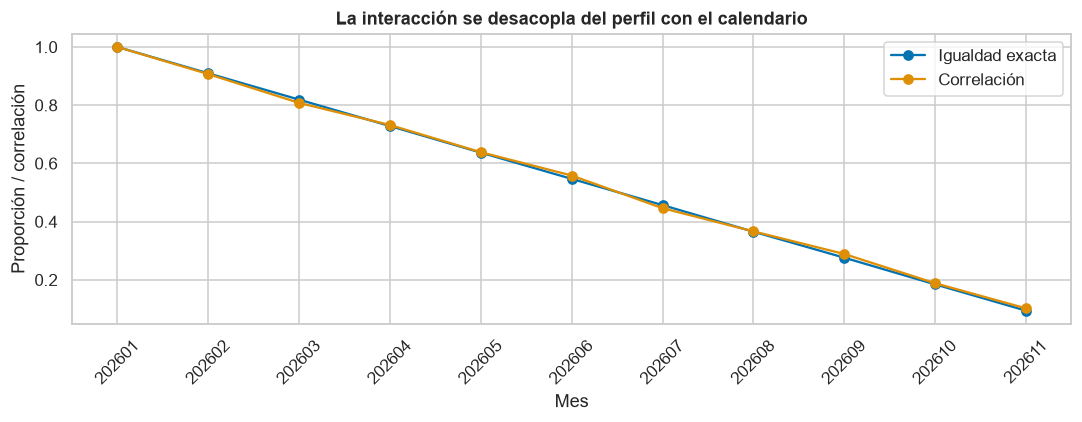

,n_features
perfil,22
historia,33
dinamica,46
cruces,75
completo,88
foco,13


In [4]:
# No se lee test para elegir transformaciones o modelos.
raw = pd.read_csv('train.csv')
d, groups = make_features(raw)
quirk = raw.groupby('mes').apply(lambda z: pd.Series({
    'igualdad_recencias': z.dias_ultima_interaccion.eq(z.dias_ultima_transaccion).mean(),
    'correlacion_recencias': z.dias_ultima_interaccion.corr(z.dias_ultima_transaccion),
}), include_groups=False)
display(quirk)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(quirk.index.astype(str), quirk.igualdad_recencias, marker='o', label='Igualdad exacta')
ax.plot(quirk.index.astype(str), quirk.correlacion_recencias, marker='o', label='Correlación')
ax.set(title='La interacción se desacopla del perfil con el calendario', xlabel='Mes', ylabel='Proporción / correlación')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout(); plt.savefig(OUT / '01_recencias.png'); plt.show()
display(pd.Series({k: len(v) for k, v in groups.items()}, name='n_features').to_frame())

La igualdad de recencias cae casi linealmente de 100% en enero a 9.4% en noviembre.
Es evidencia de un mecanismo de degradación/cambio por calendario, no prueba de una actividad real.
Por eso ensayamos historia dinámica como ablación y añadimos un modelo de foco que prescinde de ella.
No entrenamos un modelo que aproveche la ausencia futura: esa ausencia equivale al evento.

In [5]:
# Pruebas automáticas: prefijos, futuro perturbado, labels contemporáneos y autoexclusión de cliente.
checks = leakage_tests(raw)
display(pd.DataFrame({'auditoría': checks}))
pd.DataFrame({'auditoría': checks}).to_csv(OUT / 'auditoria_leakage.csv', index=False)
enc_example, enc_names = past_encoding(d, 202608)
display(enc_example.loc[enc_example.mes.eq(202608), ['id_cliente', 'mes', 'banda_riesgo'] + enc_names].head())

,auditoría
0,Identidades de features de dominio: OK
1,Apertura estimada estable dentro de cliente: OK
2,Invariancia al truncar futuro: OK
3,Perturbación de covariables/labels futuros: OK
4,Encodings congelados al origen: OK
5,Exclusión completa del propio cliente: OK
6,Exclusión de labels del mismo mes: OK
7,Encodings invariantes al truncar panel: OK
8,Features numéricas finitas: OK


,id_cliente,mes,banda_riesgo,te_banda_riesgo,freq_banda_riesgo,te_riesgo_productos,freq_riesgo_productos,te_riesgo_tx,freq_riesgo_tx,te_riesgo_movil,freq_riesgo_movil
13,2,202608,low,0.187897,0.482069,0.186154,0.141850,0.169900,0.132583,0.203943,0.313298
24,3,202608,high,0.088188,0.196062,0.083435,0.057372,0.055643,0.049229,0.088720,0.132454
42,7,202608,low,0.187897,0.482069,0.136053,0.227311,0.181183,0.115314,0.203943,0.313298
53,8,202608,high,0.088188,0.196062,0.100451,0.015546,0.154230,0.028857,0.089299,0.063508
68,10,202608,high,0.088188,0.196062,0.083435,0.057372,0.055643,0.049229,0.088720,0.132454


## 3. Modelos y protocolo fijados antes de evaluar

**Ablaciones:** CatBoost perfil, historia básica, historia dinámica, cruces, todos los features,
mayor profundidad, encoding temporal y un subconjunto enfocado. Los primeros cinco comparten
parámetros, por lo que sus diferencias permiten estudiar grupos de features. Todos usan one-hot
interno (`one_hot_max_size=255`), sin target statistics aleatorias de categorías.
**Familias nuevas:** regresión logística aditiva con splines y cruces (GAM aproximado) y boosting
de histogramas regularizado. La complejidad de GAM está en sus bases no lineales y cruces explícitos.

No se usan pesos inversos a la longitud final, SMOTE ni balanceo de clases. La unidad de loss es
cliente-mes elegible; igualar pesos por cliente cambiaría la población objetivo y podría usar futuro.
Los IDs se usan exclusivamente para joins y cálculo causal de historia.

Para agosto se entrena enero-julio, para septiembre enero-agosto y para octubre enero-septiembre.
Se evalúan 10 especificaciones predefinidas. No hay early stopping ni eval_set en ningún modelo.
Una media 50/50 de los dos mejores individuales será candidata; se acepta únicamente si mejora
la AUC media de selección en al menos 0.0005. Ese conjunto de selección no es un test independiente.

In [6]:
display(pd.DataFrame(SPECS).T)
fold_rows, predictions, fitted = [], {}, {}
selection_months = [202608, 202609, 202610]
for month in selection_months:
    pred = d.loc[d.mes.eq(month), ['id_cliente', 'mes', 'objetivo', 'primera_obs']].reset_index(drop=True)
    for name, spec in SPECS.items():
        start = time.perf_counter()
        p, model, features = fit_predict(spec, d, groups, month)
        pred[name] = p
        row = dict(modelo=name, mes=month, n_features=len(features), segundos=time.perf_counter()-start, **metrics(pred.objetivo, p))
        fold_rows.append(row)
        if month == 202610:
            fitted[name] = (model, features)
        print(f'{month} {name}: AUC={row["AUC"]:.4f}, {row["segundos"]:.1f}s', flush=True)
    predictions[month] = pred
    pred.to_csv(OUT / f'predicciones_{month}.csv', index=False)
folds = pd.DataFrame(fold_rows)
folds.to_csv(OUT / 'backtest_individual.csv', index=False)
summary = folds.groupby('modelo').agg(AUC_media=('AUC', 'mean'), AUC_sd=('AUC', 'std'),
    LogLoss_media=('LogLoss', 'mean'), Brier_media=('Brier', 'mean'), lift10_medio=('lift10', 'mean'))
summary = summary.sort_values('AUC_media', ascending=False)
display(summary)

,family,group,depth,l2,trees,encoding
CB_perfil,cat,perfil,5,NaN,NaN,NaN
CB_historia,cat,historia,5,NaN,NaN,NaN
CB_dinamica,cat,dinamica,5,NaN,NaN,NaN
CB_cruces,cat,cruces,5,NaN,NaN,NaN
CB_completo,cat,completo,5,NaN,NaN,NaN
CB_completo_profundo,cat,completo,7,25,350,NaN
CB_encoding_pasado,cat,cruces,5,NaN,NaN,True
CB_foco,cat,foco,4,20,NaN,NaN
GAM_splines,spline,cruces,NaN,NaN,NaN,NaN
HGB_completo,hgb,completo,NaN,NaN,NaN,NaN


202608 CB_perfil: AUC=0.6343, 9.7s


202608 CB_historia: AUC=0.6323, 6.8s


202608 CB_dinamica: AUC=0.6321, 5.2s


202608 CB_cruces: AUC=0.6325, 6.9s


...

202610 CB_encoding_pasado: AUC=0.6311, 10.3s


202610 CB_foco: AUC=0.6296, 3.9s


202610 GAM_splines: AUC=0.6223, 9.4s


202610 HGB_completo: AUC=0.6315, 12.6s


,AUC_media,AUC_sd,LogLoss_media,Brier_media,lift10_medio
modelo,,,,,
CB_historia,0.630784,0.003280,0.400915,0.121036,2.042199
CB_perfil,0.630449,0.005481,0.400804,0.121036,2.071901
CB_completo,0.629478,0.004729,0.400932,0.121026,2.042132
CB_dinamica,0.629437,0.005916,0.401232,0.121101,2.050161
CB_cruces,0.629292,0.004219,0.400772,0.120992,2.080480
HGB_completo,0.629081,0.006029,0.400754,0.121010,2.036883
CB_encoding_pasado,0.628420,0.003613,0.400914,0.121069,2.056045
CB_completo_profundo,0.626418,0.004266,0.401603,0.121178,2.032603
CB_foco,0.626127,0.003184,0.401120,0.121042,2.053153


,modelo,mes,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,lift10
0,Ensamble_50_50,202608,0.633752,0.267503,0.395541,0.119037,0.233242,0.144179,0.144042,1.953071
1,Ensamble_50_50,202609,0.626054,0.252109,0.390493,0.116839,0.229610,0.140707,0.141796,2.060302
2,Ensamble_50_50,202610,0.633537,0.267075,0.416203,0.127145,0.256750,0.156538,0.141732,2.180590


SELECCIÓN CONGELADA: CB_historia ['CB_historia']


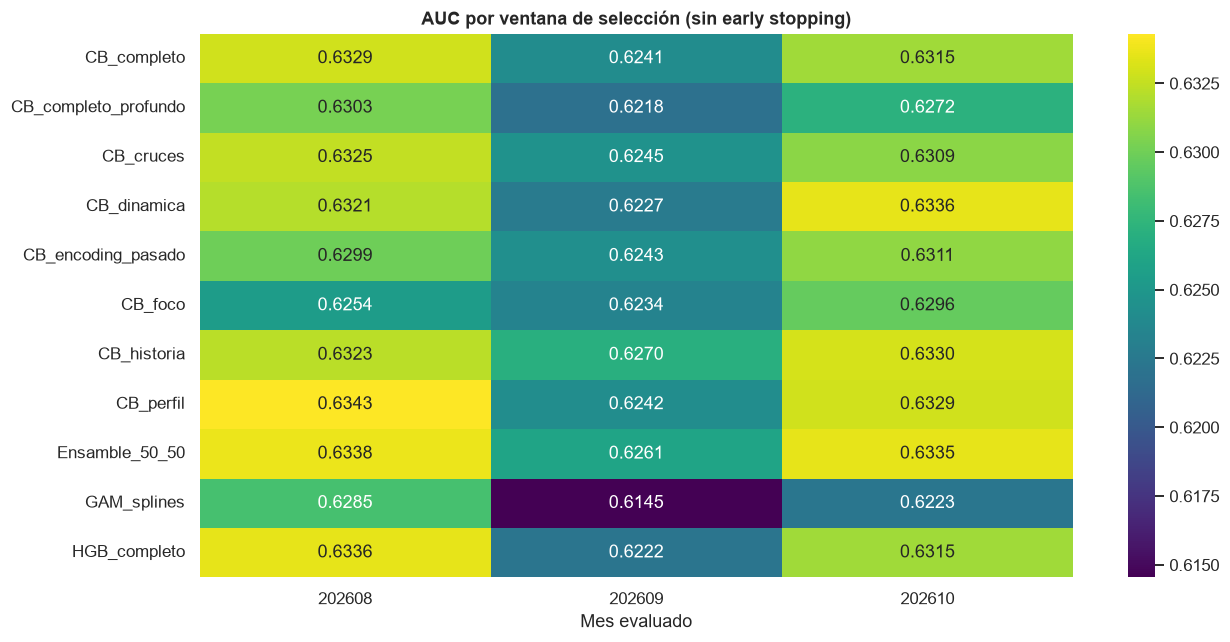

In [7]:
# Congelamos la elección antes de evaluar noviembre.
top2 = summary.index[:2].tolist()
ensemble_rows = []
for month, pred in predictions.items():
    pred['Ensamble_50_50'] = pred[top2].mean(axis=1)
    ensemble_rows.append(dict(modelo='Ensamble_50_50', mes=month, **metrics(pred.objetivo, pred.Ensamble_50_50)))
ensemble_mean = pd.DataFrame(ensemble_rows).AUC.mean()
use_ensemble = bool(ensemble_mean > summary.iloc[0].AUC_media + .0005)
chosen = 'Ensamble_50_50' if use_ensemble else top2[0]
members = top2 if use_ensemble else [top2[0]]
weights = [1 / len(members)] * len(members)
manifest = dict(selected=chosen, members=members, weights=weights, selection_months=selection_months,
    mean_auc_individual=float(summary.iloc[0].AUC_media), mean_auc_ensemble=float(ensemble_mean),
    decision_rule='AUC media ago-oct; mezcla 50/50 solo si mejora >=0.0005', specs=SPECS,
    target='hazard mensual', availability='covariables antes de evento; etiquetas t-1 disponibles en t',
    train_sha256=hashlib.sha256(Path('train.csv').read_bytes()).hexdigest(), python=platform.python_version())
(OUT / 'seleccion_congelada.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame(ensemble_rows))
print('SELECCIÓN CONGELADA:', chosen, members)
summary.to_csv(OUT / 'comparacion_seleccion.csv')
selection_all = pd.concat([folds, pd.DataFrame(ensemble_rows)], ignore_index=True)
fig, ax = plt.subplots(figsize=(12, 6))
heat = selection_all.pivot(index='modelo', columns='mes', values='AUC')
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis', ax=ax)
ax.set(title='AUC por ventana de selección (sin early stopping)', xlabel='Mes evaluado', ylabel='')
plt.tight_layout(); plt.savefig(OUT / '02_seleccion.png'); plt.show()

## 4. Qué aportan los grupos de features

Las diferencias usan exactamente las mismas filas de cada mes. No atribuimos a features una mejora
que podría deberse a cambiar profundidad, algoritmo o regularización. La importancia de CatBoost
describe uso interno, no causalidad. Una mejora negativa es un resultado válido del experimento.

mes,202608,202609,202610,media_delta
modelo,,,,
CB_perfil,0.002007,-0.002847,-0.000166,-0.000335
CB_historia,0.000000,0.000000,0.000000,0.000000
CB_dinamica,-0.000213,-0.004360,0.000533,-0.001347
CB_cruces,0.000195,-0.002511,-0.002160,-0.001492
CB_completo,0.000586,-0.002944,-0.001562,-0.001306


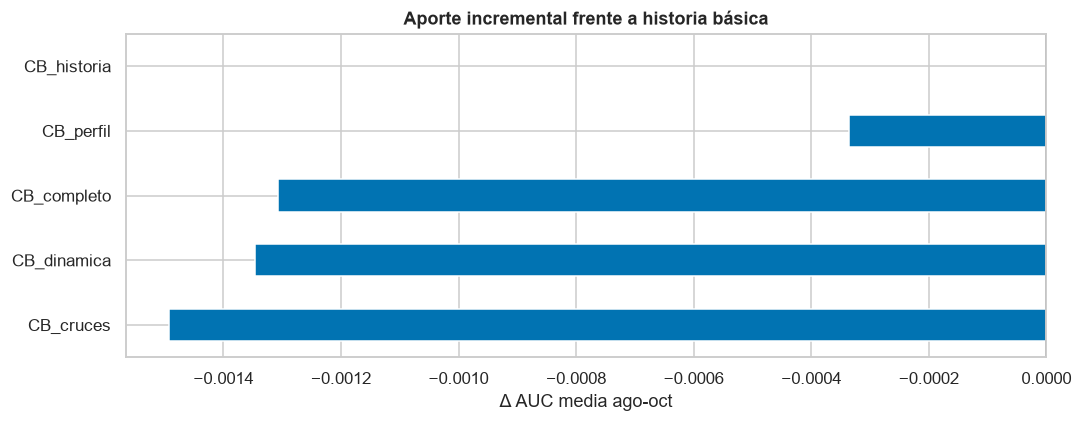

,importancia
banda_riesgo,36.548791
numero_productos,14.961905
dias_ultima_transaccion,10.514538
activo_movil,5.278251
tiene_tarjeta_credito,3.214593
ratio_deuda_ingresos,2.629248
canal_adquisicion,2.578778
inter_lag1,2.224774
dias_ultima_interaccion,2.069974
saldo_promedio,1.866193


In [8]:
ablations = heat.loc[['CB_perfil', 'CB_historia', 'CB_dinamica', 'CB_cruces', 'CB_completo']].copy()
delta = ablations.subtract(heat.loc['CB_historia'], axis=1)
delta['media_delta'] = delta.mean(axis=1)
display(delta)
delta.to_csv(OUT / 'ablaciones_delta_auc.csv')
fig, ax = plt.subplots(figsize=(10, 4))
delta.media_delta.sort_values().plot.barh(ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Aporte incremental frente a historia básica', xlabel='Δ AUC media ago-oct', ylabel='')
plt.tight_layout(); plt.savefig(OUT / '03_ablaciones.png'); plt.show()
cat_name = next(n for n in summary.index if SPECS[n]['family'] == 'cat')
model, features = fitted[cat_name]
importance = pd.Series(model.get_feature_importance(), index=features, name='importancia').sort_values(ascending=False)
display(importance.head(20).to_frame())
importance.to_csv(OUT / 'importancia_modelo_octubre.csv')

## 5. Evaluación de noviembre con decisión congelada

Se reentrenan candidatos enero-octubre con la especificación ya fijada y se evalúan una vez.
Mostrar todos permite comparar, pero el candidato para diciembre sigue siendo el elegido en ago-oct,
aunque otro resulte mejor en noviembre. No se reajusta calibración ni mezcla con noviembre.

In [9]:
nov = d.loc[d.mes.eq(202611), ['id_cliente', 'mes', 'objetivo', 'primera_obs']].reset_index(drop=True)
final_rows = []
for name, spec in SPECS.items():
    start = time.perf_counter()
    p, _, features = fit_predict(spec, d, groups, 202611)
    nov[name] = p
    final_rows.append(dict(modelo=name, **metrics(nov.objetivo, p)))
    print(f'Noviembre {name}: AUC={final_rows[-1]["AUC"]:.4f}', flush=True)
nov['Ensamble_50_50'] = nov[top2].mean(axis=1)
final_rows.append(dict(modelo='Ensamble_50_50', **metrics(nov.objetivo, nov.Ensamble_50_50)))
prior = np.repeat(d.loc[d.mes.lt(202611), 'objetivo'].mean(), len(nov))
final_rows.append(dict(modelo='Prior', **metrics(nov.objetivo, prior)))
final = pd.DataFrame(final_rows).set_index('modelo')
final['seleccionado_antes_de_noviembre'] = final.index == chosen
display(final.sort_values('AUC', ascending=False))
nov.to_csv(OUT / 'predicciones_noviembre.csv', index=False)
final.to_csv(OUT / 'metricas_noviembre.csv')

Noviembre CB_perfil: AUC=0.6179


Noviembre CB_historia: AUC=0.6209


Noviembre CB_dinamica: AUC=0.6190


Noviembre CB_cruces: AUC=0.6172


Noviembre CB_completo: AUC=0.6145


...

Noviembre CB_encoding_pasado: AUC=0.6197


Noviembre CB_foco: AUC=0.6188


Noviembre GAM_splines: AUC=0.6088


Noviembre HGB_completo: AUC=0.6217


,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,lift10,seleccionado_antes_de_noviembre
modelo,,,,,,,,,
HGB_completo,0.621690,0.243380,0.409846,0.124659,0.227987,0.151474,0.148009,1.876303,False
CB_historia,0.620884,0.241767,0.409864,0.124549,0.230134,0.151474,0.148031,1.890202,True
CB_encoding_pasado,0.619723,0.239447,0.409867,0.124574,0.228222,0.151474,0.146382,1.938846,False
Ensamble_50_50,0.619567,0.239135,0.410074,0.124627,0.229108,0.151474,0.143368,1.897151,False
CB_dinamica,0.619030,0.238060,0.410180,0.124665,0.228006,0.151474,0.148228,1.897151,False
CB_foco,0.618802,0.237603,0.410181,0.124624,0.228234,0.151474,0.141269,1.890202,False
CB_perfil,0.617888,0.235776,0.410633,0.124795,0.227934,0.151474,0.138706,1.945796,False
CB_cruces,0.617156,0.234312,0.410246,0.124686,0.226037,0.151474,0.146988,1.924948,False
CB_completo_profundo,0.616594,0.233188,0.410436,0.124694,0.229788,0.151474,0.146678,1.890202,False


In [10]:
# Bootstrap PAREADO: mismos clientes resampleados para ambos scores; no basta solapamiento de IC individuales.
rng = np.random.default_rng(SEED)
y = nov.objetivo.to_numpy()
p_chosen, p_base = nov[chosen].to_numpy(), nov.CB_historia.to_numpy()
boot = []
for _ in range(800):
    idx = rng.integers(0, len(y), size=len(y))
    a = roc_auc_score(y[idx], p_chosen[idx])
    b = roc_auc_score(y[idx], p_base[idx])
    boot.append([a, a-b])
ci = pd.DataFrame(np.quantile(boot, [.025, .5, .975], axis=0),
                  index=['p2.5', 'mediana', 'p97.5'], columns=['AUC_seleccionado', 'delta_vs_CB_historia'])
display(ci)
ci.to_csv(OUT / 'bootstrap_pareado_noviembre.csv')
# Una fila por cliente en noviembre: bootstrap por fila equivale a por cliente.
# Este IC es condicional a modelos entrenados; no incluye variabilidad de reentrenamiento/selección.
subrows = []
for name in list(dict.fromkeys(['CB_historia', chosen])):
    for first, label in [(1, 'primera observación'), (0, 'recurrente')]:
        subset = nov.loc[nov.primera_obs.eq(first)]
        subrows.append(dict(modelo=name, segmento=label, n=len(subset), **metrics(subset.objetivo, subset[name])))
segments = pd.DataFrame(subrows)
display(segments)
segments.to_csv(OUT / 'segmentos_noviembre.csv', index=False)

,AUC_seleccionado,delta_vs_CB_historia
p2.5,0.605375,0.0
mediana,0.620607,0.0
p97.5,0.635454,0.0


,modelo,segmento,n,AUC,Gini,LogLoss,Brier,AP,tasa,pred_media,lift10
0,CB_historia,primera observación,728,0.601662,0.203323,0.487072,0.155081,0.280331,0.196429,0.175961,1.534247
1,CB_historia,recurrente,8772,0.620364,0.240728,0.403456,0.122016,0.225030,0.147743,0.145713,1.958091


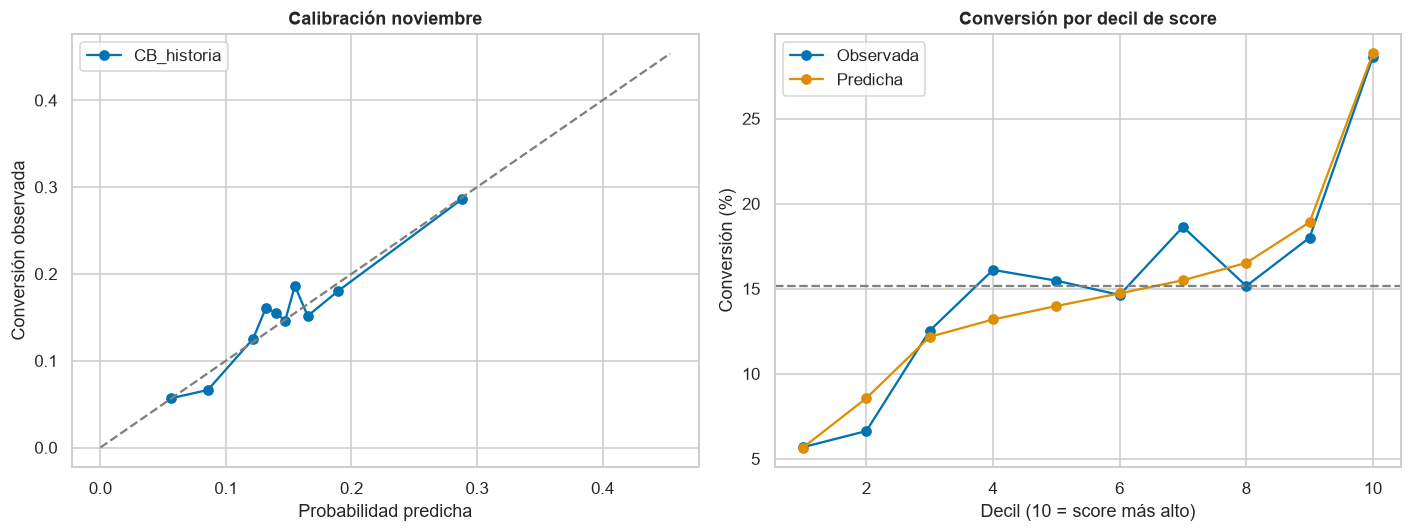

,n,real,pred
decil,,,
1,950,0.056842,0.056615
2,950,0.066316,0.085619
3,950,0.125263,0.121669
4,950,0.161053,0.131904
5,950,0.154737,0.139806
6,950,0.146316,0.147233
7,950,0.186316,0.154949
8,950,0.151579,0.165161
9,950,0.180000,0.189073


In [11]:
# Calibración y lift: no ajustar usando labels de este gráfico.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in list(dict.fromkeys(['CB_historia', chosen])):
    actual, predicted = calibration_curve(y, nov[name], n_bins=10, strategy='quantile')
    axes[0].plot(predicted, actual, marker='o', label=name)
upper = max(.4, float(nov[chosen].max()))
axes[0].plot([0, upper], [0, upper], '--', color='grey')
axes[0].set(title='Calibración noviembre', xlabel='Probabilidad predicha', ylabel='Conversión observada')
axes[0].legend()
decile = pd.qcut(nov[chosen], 10, labels=False, duplicates='drop') + 1
lift = nov.assign(decil=decile).groupby('decil').agg(n=('objetivo','size'), real=('objetivo','mean'), pred=(chosen,'mean'))
axes[1].plot(lift.index, lift.real*100, 'o-', label='Observada')
axes[1].plot(lift.index, lift.pred*100, 'o-', label='Predicha')
axes[1].axhline(y.mean()*100, color='grey', linestyle='--')
axes[1].set(title='Conversión por decil de score', xlabel='Decil (10 = score más alto)', ylabel='Conversión (%)')
axes[1].legend()
plt.tight_layout(); plt.savefig(OUT / '04_calibracion_lift.png'); plt.show()
display(lift)

## 6. Entrenamiento final y predicción reproducible

Diciembre se abre únicamente después de congelar la selección y completar la evaluación.
Se reentrenan los miembros elegidos con enero-noviembre. Para los encodings de diciembre se permiten
etiquetas hasta noviembre; para cada fila de entrenamiento, solo las de meses anteriores a esa fila.
Se conserva el baseline anterior. El orden de entrega se restaura explícitamente mediante id_cliente.

In [12]:
test = pd.read_csv('test.csv')
assert test.mes.eq(202612).all() and test.id_cliente.is_unique
all_raw = pd.concat([raw, test.assign(objetivo=np.nan)], ignore_index=True)
all_d, all_groups = make_features(all_raw)
dec = all_d.loc[all_d.mes.eq(202612), ['id_cliente', 'mes']].copy()
dec['prediccion'] = 0.0
model_bundle = []
for name, weight in zip(members, weights):
    pred, model, features = fit_predict(SPECS[name], all_d, all_groups, 202612)
    dec['prediccion'] += weight * pred
    model_bundle.append(dict(name=name, weight=weight, spec=SPECS[name], features=features, model=model))
joblib.dump(model_bundle, OUT / 'modelos_finales.joblib')
submission = test[['id_cliente']].merge(dec[['id_cliente', 'prediccion']], on='id_cliente', how='left', validate='one_to_one', sort=False)
assert submission.id_cliente.equals(test.id_cliente)
assert submission.prediccion.notna().all() and submission.prediccion.between(0, 1).all()
sample = pd.read_csv('sample_submission.csv')
assert list(submission.columns) == list(sample.columns) and submission.id_cliente.equals(sample.id_cliente)
submission.to_csv('submission_feature_engineering.csv', index=False)
display(submission.prediccion.describe().to_frame())
print('Predicción final:', chosen, '| filas:', len(submission))

,prediccion
count,9900.000000
mean,0.151193
std,0.063246
min,0.028122
25%,0.127187
50%,0.148016
75%,0.167210
max,0.438671


Predicción final: CB_historia | filas: 9900


## 7. Interpretación y límites

La mejora de encodings/cruces puede capturar regularidades del generador y no comportamiento causal.
No se reconstruyen edades/antigüedades reales ni se transforman recencias sintéticas en transacciones.
La ausencia de fuga comprobada en código depende del supuesto de disponibilidad temporal del CSV.
La selección entre muchos candidatos introduce optimismo en ago-oct; noviembre también tiene historia
de exploración en el proyecto. Diciembre carece de labels, por lo que no afirmamos su rendimiento.

In [13]:
# Conclusiones calculadas desde resultados; no se promete una mejora antes de observarla.
selected_metrics = final.loc[chosen]
baseline_metrics = final.loc['CB_historia']
change = selected_metrics.AUC - baseline_metrics.AUC
ci_low, ci_high = ci.loc['p2.5', 'delta_vs_CB_historia'], ci.loc['p97.5', 'delta_vs_CB_historia']
evidence = 'El IC pareado queda por encima de cero.' if ci_low > 0 else 'El IC pareado incluye cero o valores negativos: no demuestra superioridad.'
report = f'''Modelo congelado en selección: **{chosen}** ({', '.join(members)}).

En noviembre: AUC **{selected_metrics.AUC:.4f}**, Gini **{selected_metrics.Gini:.4f}**,
log-loss **{selected_metrics.LogLoss:.4f}**, Brier **{selected_metrics.Brier:.4f}**.
Control CatBoost con historia bajo el mismo protocolo: AUC **{baseline_metrics.AUC:.4f}**.
Δ AUC **{change:+.4f}**; IC bootstrap pareado 95% **[{ci_low:+.4f}, {ci_high:+.4f}]**. {evidence}

El decil superior tiene lift **{selected_metrics.lift10:.2f}×** sobre la tasa media.
La probabilidad media predicha es **{selected_metrics.pred_media:.2%}**, frente a **{y.mean():.2%}** observado.
La calibración se evalúa, pero no se ajusta con noviembre.

Mejor ablación media frente a historia: **{delta.media_delta.idxmax()}**
(Δ AUC {delta.media_delta.max():+.4f}); historia dinámica: **{delta.loc['CB_dinamica','media_delta']:+.4f}**;
cruces: **{delta.loc['CB_cruces','media_delta']:+.4f}**; todas juntas: **{delta.loc['CB_completo','media_delta']:+.4f}**.

Se entrega submission_feature_engineering.csv, modelos finales, manifiesto de selección, métricas,
predicciones por mes y pruebas de causalidad. La predicción es reproducible con fe_hazard.py y
predecir_features.py. El notebook anterior se conserva como registro exploratorio, no como control sin sesgo.
'''
display(Markdown(report))
(OUT / 'informe_resultados.md').write_text(report, encoding='utf-8')

Modelo congelado en selección: **CB_historia** (CB_historia).

En noviembre: AUC **0.6209**, Gini **0.2418**,
log-loss **0.4099**, Brier **0.1245**.
Control CatBoost con historia bajo el mismo protocolo: AUC **0.6209**.
Δ AUC **+0.0000**; IC bootstrap pareado 95% **[+0.0000, +0.0000]**. El IC pareado incluye cero o valores negativos: no demuestra superioridad.

El decil superior tiene lift **1.89×** sobre la tasa media.
La probabilidad media predicha es **14.80%**, frente a **15.15%** observado.
La calibración se evalúa, pero no se ajusta con noviembre.

Mejor ablación media frente a historia: **CB_historia**
(Δ AUC +0.0000); historia dinámica: **-0.0013**;
cruces: **-0.0015**; todas juntas: **-0.0013**.

Se entrega submission_feature_engineering.csv, modelos finales, manifiesto de selección, métricas,
predicciones por mes y pruebas de causalidad. La predicción es reproducible con fe_hazard.py y
predecir_features.py. El notebook anterior se conserva como registro exploratorio, no como control sin sesgo.


1019